# China Dataset: Preprocessing and Cost Prediction

This notebook explores the China software project dataset, compares baseline regression models, engineers features, and evaluates a tuned XGBoost model.

## Data Preprocessing and Feature Preparation

The dataset is inspected and prepared before applying machine learning algorithms. This stage focuses on understanding the available features, checking data quality, and organizing the input variables and target variable for model training.

Appropriate preprocessing helps maintain data consistency and improves the reliability of subsequent model evaluation.

In [1]:
import pandas as pd
from pathlib import Path

csv_path = Path("../data/processed/china.csv")

if not csv_path.exists():
    csv_path = Path("data/processed/china.csv")

df = pd.read_csv(csv_path)

print("Dataset loaded:", csv_path.resolve())
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset loaded: C:\Users\kumaw\Downloads\Software-Cost-Estimation-main\Software-Cost-Estimation-main\data\processed\china.csv
Dataset shape: (499, 19)
Columns: ['ID', 'AFP', 'Input', 'Output', 'Enquiry', 'File', 'Interface', 'Added', 'Changed', 'Deleted', 'PDR_AFP', 'PDR_UFP', 'NPDR_AFP', 'NPDU_UFP', 'Resource', 'Dev.Type', 'Duration', 'N_effort', 'Effort']


In [2]:

df.columns

Index(['ID', 'AFP', 'Input', 'Output', 'Enquiry', 'File', 'Interface', 'Added',
       'Changed', 'Deleted', 'PDR_AFP', 'PDR_UFP', 'NPDR_AFP', 'NPDU_UFP',
       'Resource', 'Dev.Type', 'Duration', 'N_effort', 'Effort'],
      dtype='str')

In [3]:
df.shape

(499, 19)

In [4]:
hourly_rate = 50.0  # currency units per effort unit

df['Cost'] = df['Effort'] * hourly_rate

# use cost as the target for prediction
X = df.drop(columns=['Effort', 'Cost'])
y = df['Cost']


in the above block we are seperating features and target and below we are spliting the data for training and testing 

## Model Training and Evaluation Strategy

The prepared dataset is divided into training and testing subsets to evaluate the model on unseen observations. Multiple regression approaches are considered to study their ability to estimate software development effort.

Model performance is assessed using regression evaluation metrics. Comparing these results helps identify the strengths and limitations of the selected estimation approach.

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Train shape: ", X_train.shape)
print("Test shape:", X_test.shape)

Train shape:  (399, 18)
Test shape: (100, 18)


In [6]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [7]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# baseline linear regression (no log-transform, single split, no CV)
#Train
model = LinearRegression()
model.fit(X_train_scaled, y_train)

#Predict
y_pred = model.predict(X_test_scaled)

#Evaluate 
mse = mean_squared_error(y_test, y_pred)
r2= r2_score(y_test, y_pred)

print("MSE: ", mse)
print("R2 Score: ", r2)


MSE:  4199968756.1969934
R2 Score:  0.9441077176299267


In [8]:
# baseline random forest (reference model)
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

mse_rf = mean_squared_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest MSE:", mse_rf)
print("Random Forest R2:", r2_rf)


Random Forest MSE: 6508205814.9175
Random Forest R2: 0.9133901944881849


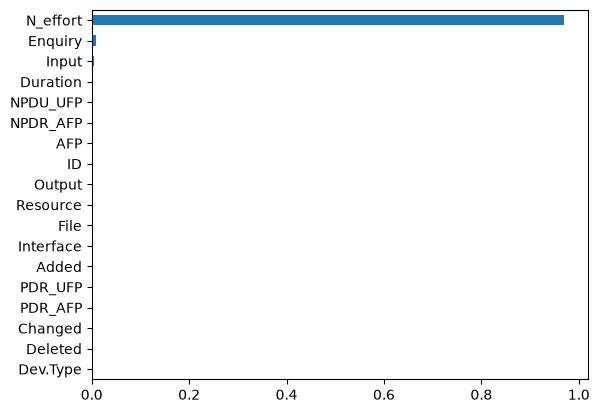

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

feature_importance = pd.Series(rf.feature_importances_, index=X.columns)
feature_importance.sort_values().plot(kind='barh')
plt.show()

In [10]:
# ------------------------------
# Step 1: Feature Engineering
# ------------------------------

import pandas as pd
import numpy as np
import os

# 1️⃣ Load the CSV (update path if needed)
csv_path = os.path.join("..", "data", "processed", "china.csv")  # Adjust folder if different
df = pd.read_csv(csv_path)
print("CSV loaded successfully! Shape:", df.shape)

# 2️⃣ Combine related columns into Functional_Size
df['Functional_Size'] = df['Input'] + df['Output'] + df['Enquiry'] + df['File'] + df['Interface']

# 3️⃣ Create feature ratios / interactions
df['Added_Deleted_Ratio'] = df['Added'] / (df['Deleted'] + 1)          # +1 avoids division by zero
df['Change_Per_Duration'] = (df['Added'] + df['Changed'] + df['Deleted']) / (df['Duration'] + 1)

# 4️⃣ Drop unhelpful or redundant columns
df = df.drop(columns=['ID','Dev.Type','Input','Output','Enquiry','File','Interface','Deleted','Changed'])

# 5️⃣ Compute cost based on effort and a rate
hourly_rate = 50.0  # change to your currency/unit
# cost is linear so SHAP explanations will still apply after multiplying by rate

df['Cost'] = df['Effort'] * hourly_rate

df['Log_Cost'] = np.log1p(df['Cost'])   # log(1 + Cost) avoids log(0)

# ✅ Check the final dataframe
print("\nColumns after feature engineering:")
print(df.columns)
print("\nSample data:")
print(df.head())


CSV loaded successfully! Shape: (499, 19)

Columns after feature engineering:
Index(['AFP', 'Added', 'PDR_AFP', 'PDR_UFP', 'NPDR_AFP', 'NPDU_UFP',
       'Resource', 'Duration', 'N_effort', 'Effort', 'Functional_Size',
       'Added_Deleted_Ratio', 'Change_Per_Duration', 'Cost', 'Log_Cost'],
      dtype='str')

Sample data:
      AFP   Added  PDR_AFP  PDR_UFP  NPDR_AFP  NPDU_UFP  Resource  Duration  \
0  1587.0  1502.0      4.7      5.0       4.7       5.0       4.0       4.0   
1   260.0    51.0     16.0     16.6      16.0      16.6       2.0      17.0   
2   152.0   163.0      4.4      4.1       4.4       4.1       1.0       9.0   
3   252.0    69.0     12.8     14.3      15.5      17.3       1.0       4.0   
4   292.0     0.0     10.3      9.8      12.4      11.7       1.0      13.0   

   N_effort  Effort  Functional_Size  Added_Deleted_Ratio  \
0    7490.0  7490.0           1502.0          1502.000000   
1    4150.0  4150.0            250.0             0.822581   
2     668.0   66

In [11]:
# ------------------------------
# Step 2: Train/Test Split + tuned XGBoost pipeline (predicting cost)
# ------------------------------
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
import xgboost as xgb

# drop the leakage column (N_effort) before modelling
features = ['AFP','Added','Resource','Duration',
            'Functional_Size','Added_Deleted_Ratio','Change_Per_Duration']
target = 'Log_Cost'   # using log-transformed cost

X = df[features]
y = df[target]

# split once and reuse for all models
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Train shape: ", X_train.shape)
print("Test shape:", X_test.shape)

# build a preprocessing+model pipeline
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('xgb', xgb.XGBRegressor(objective='reg:squarederror', random_state=42))
])

# grid of hyper-parameters
param_grid = {
    'xgb__n_estimators': [100, 200, 300],
    'xgb__max_depth': [3, 5, 7],
    'xgb__learning_rate': [0.01, 0.1],
    'xgb__subsample': [0.7, 1.0]
}

grid = GridSearchCV(
    pipe, param_grid,
    cv=5, scoring='r2', n_jobs=-1, verbose=1
)
grid.fit(X_train, y_train)

print("Best parameters found:")
print(grid.best_params_)

best_model = grid.best_estimator_

# evaluate on hold-out test set
y_pred_log = best_model.predict(X_test)
# back-transform predictions and truth to original cost units
y_pred = np.expm1(y_pred_log)
y_test_orig = np.expm1(y_test)

print("\nFinal test set results (in cost units):")
print("MSE:", mean_squared_error(y_test_orig, y_pred))
print("R² score:", r2_score(y_test_orig, y_pred))


Train shape:  (399, 7)
Test shape: (100, 7)
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best parameters found:
{'xgb__learning_rate': 0.01, 'xgb__max_depth': 3, 'xgb__n_estimators': 300, 'xgb__subsample': 1.0}

Final test set results (in cost units):
MSE: 42782646421.42228
R² score: 0.4306577279183499


## Model Interpretability Using SHAP

Model predictions alone do not explain why a particular software project receives an estimated effort value. SHAP (SHapley Additive exPlanations) is used to investigate how individual input features contribute to model predictions. It provides an interpretable framework for understanding the relationship between the input variables and the output generated by a machine learning model.

SHAP is based on the concept of Shapley values from cooperative game theory, where each feature is treated as a contributor to the final prediction. It estimates the contribution of each feature by considering how the model's prediction changes when that feature is included in different feature combinations. This approach helps explain both the direction and magnitude of a feature's influence on the predicted value.

In software effort estimation, features such as project size, development duration, team characteristics, and other project-related attributes may influence the model's predictions, depending on the dataset and the features used during training. SHAP explanations help identify which of the available input features have the greatest influence on the model's output.

The SHAP summary plot provides a global view of feature importance across multiple observations, helping compare the relative influence of different features. Local explanations, on the other hand, focus on an individual project and show how its feature values contribute to the specific prediction. Together, these visualizations provide insights into both the overall behavior of the model and its predictions for individual projects.

The resulting explanations help interpret feature influence and provide additional insight into the model's software effort estimation behavior. This improves transparency and makes it easier to investigate model predictions, communicate findings, and identify patterns that may require further analysis.

However, SHAP values describe how features contribute to the model's predictions; they do not establish causal relationships between project attributes and software development effort. The explanations should therefore be interpreted alongside model evaluation metrics and knowledge of the underlying dataset.

c:\Users\kumaw\Downloads\Software-Cost-Estimation-main\Software-Cost-Estimation-main\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


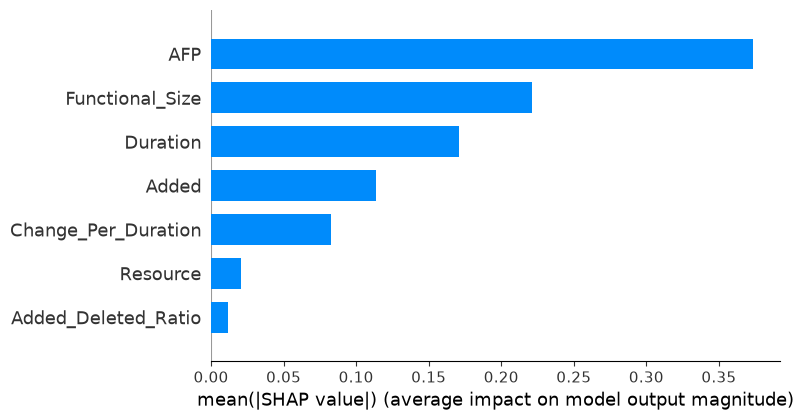

In [12]:

# SHAP explainability for the tuned XGBoost cost model
import shap
import matplotlib.pyplot as plt

# Retrieve the trained pipeline components
scaler = best_model.named_steps["scaler"]
xgb_mod = best_model.named_steps["xgb"]

# Transform the training and test features
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Use TreeExplainer with tree-path-dependent feature perturbation
explainer = shap.TreeExplainer(
    xgb_mod,
    feature_perturbation="tree_path_dependent"
)

shap_values = explainer(X_test_scaled)

# Display global feature importance
shap.summary_plot(
    shap_values,
    X_test_scaled,
    feature_names=X.columns.tolist(),
    plot_type="bar",
    show=True
)


In [13]:
# previous attempt to retrain without N_effort is no longer needed;
# the hyperparameter search above already excluded that column and
# produced the final model used for explanation.


Sample features:
        AFP   Added  Resource  Duration  Functional_Size  Added_Deleted_Ratio  \
460   276.0   177.0       1.0       4.0            244.0                 11.8   
73     75.0     0.0       1.0       5.0             69.0                  0.0   
231   105.0    21.0       1.0       8.0            105.0                 21.0   
175   722.0   622.0       1.0       9.0            622.0                622.0   
237  1710.0  1900.0       2.0      21.0           1900.0               1900.0   

     Change_Per_Duration  
460            48.800000  
73             11.500000  
231            11.666667  
175            62.200000  
237            86.363636  

Predicted log‑cost vs actual log‑cost:
predicted [11.69669  10.850667 10.826132 12.4086   13.111856]
actual    [ 9.61587214  9.63240035  9.20039104 12.24625924 13.3946795 ]

Predicted cost (first 5 rows):
[120172.234  51567.535  50317.688 244897.69  494773.03 ]

Actual cost:
460     15000.0
73      15250.0
231      9900.0
175    20

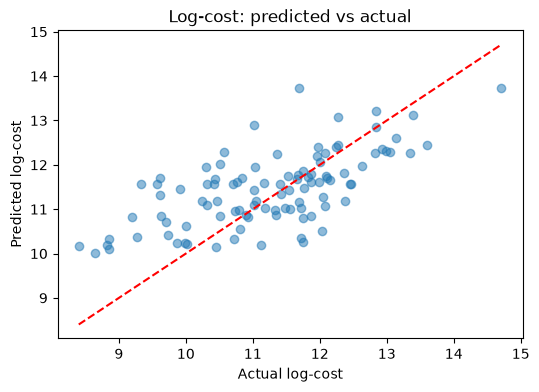

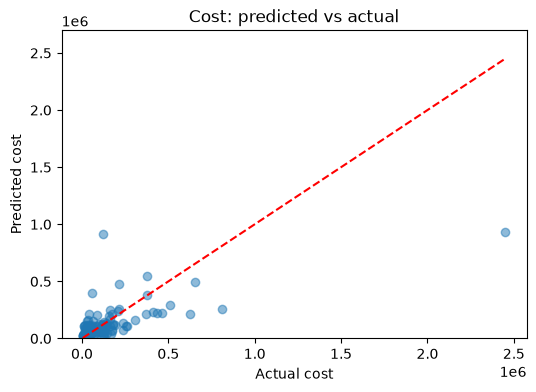

In [14]:
# ------------------------------
# Step 3: example predictions / sanity check
# ------------------------------

# take a few rows from the hold‑out set
sample = X_test.head()

# get both log‑cost and cost predictions
log_pred = best_model.predict(sample)
cost_pred = np.expm1(log_pred)

print("Sample features:")
print(sample)

# show predicted vs true on log scale
print("\nPredicted log‑cost vs actual log‑cost:")
print("predicted", log_pred)
print("actual   ", y_test.head().values)

print("\nPredicted cost (first 5 rows):")
print(cost_pred)

# true cost
true_cost = np.expm1(y_test.head())
print("\nActual cost:")
print(true_cost)

# calculate some simple error metrics for the entire test set
from sklearn.metrics import mean_absolute_error

all_log_pred = best_model.predict(X_test)
all_cost_pred = np.expm1(all_log_pred)
all_cost_true = np.expm1(y_test)

print("\nTest set MAE (cost units):", mean_absolute_error(all_cost_true, all_cost_pred))
print("Test set R² (cost units):", r2_score(all_cost_true, all_cost_pred))

# visual diagnostics: log vs raw
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.scatter(y_test, all_log_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Actual log-cost')
plt.ylabel('Predicted log-cost')
plt.title('Log-cost: predicted vs actual')
plt.show()

plt.figure(figsize=(6,4))
plt.scatter(all_cost_true, all_cost_pred, alpha=0.5)
plt.plot([all_cost_true.min(), all_cost_true.max()], [all_cost_true.min(), all_cost_true.max()], 'r--')
plt.xlabel('Actual cost')
plt.ylabel('Predicted cost')
plt.title('Cost: predicted vs actual')
plt.ylim(0, all_cost_true.max()*1.1)
plt.show()

# you can also save the pipeline for later reuse
#import joblib
#joblib.dump(best_model, 'cost_pipeline.pkl')


In [15]:
df.head()

,AFP,Added,PDR_AFP,PDR_UFP,NPDR_AFP,NPDU_UFP,Resource,Duration,N_effort,Effort,Functional_Size,Added_Deleted_Ratio,Change_Per_Duration,Cost,Log_Cost
0,1587.0,1502.0,4.7,5.0,4.7,5.0,4.0,4.0,7490.0,7490.0,1502.0,1502.000000,300.400000,374500.0,12.833350
1,260.0,51.0,16.0,16.6,16.0,16.6,2.0,17.0,4150.0,4150.0,250.0,0.822581,13.888889,207500.0,12.242891
2,152.0,163.0,4.4,4.1,4.4,4.1,1.0,9.0,668.0,668.0,163.0,163.000000,16.300000,33400.0,10.416341
3,252.0,69.0,12.8,14.3,15.5,17.3,1.0,4.0,3901.0,3238.0,226.0,13.800000,45.200000,161900.0,11.994740
4,292.0,0.0,10.3,9.8,12.4,11.7,1.0,13.0,3607.0,2994.0,307.0,0.000000,21.928571,149700.0,11.916395


MAE (cost units): 96829.64666015623
RMSE (cost units): 206839.66355953657
Median absolute error: 42920.86718750002
Median relative error: 0.5070965618946505
SMAPE (%): 66.4282373057201

Top 10 largest absolute errors:


,AFP,Added,Resource,Duration,Functional_Size,Added_Deleted_Ratio,Change_Per_Duration,true_cost,pred_cost,abs_err,rel_err
89,3331.0,2922.0,4.0,42.0,2922.0,2922.000000,67.953488,2451700.0,928141.937500,1.523558e+06,0.621429
7,2145.0,2234.0,4.0,84.0,2234.0,2234.000000,26.282353,120000.0,916948.312500,7.969483e+05,6.641236
70,846.0,729.0,1.0,13.0,729.0,729.000000,52.071429,808950.0,254932.781250,5.540172e+05,0.684860
68,769.0,178.0,1.0,8.0,747.0,13.692308,83.000000,627550.0,211140.625000,4.164094e+05,0.663548
52,1825.0,1674.0,1.0,15.0,1674.0,1674.000000,104.625000,60500.0,397437.531250,3.369375e+05,5.569215
92,3088.0,544.0,1.0,8.0,3088.0,544.000000,343.111111,213300.0,481527.000000,2.682270e+05,1.257511
15,502.0,444.0,1.0,14.0,444.0,444.000000,29.600000,464800.0,219502.781250,2.452972e+05,0.527748
12,1241.0,1240.0,1.0,15.0,1240.0,1240.000000,77.500000,511100.0,296733.937500,2.143661e+05,0.419421
91,494.0,494.0,1.0,21.0,494.0,494.000000,22.454545,435300.0,221824.359375,2.134756e+05,0.490410
47,498.0,445.0,3.0,19.0,445.0,445.000000,22.250000,411350.0,230211.890625,1.811381e+05,0.440350


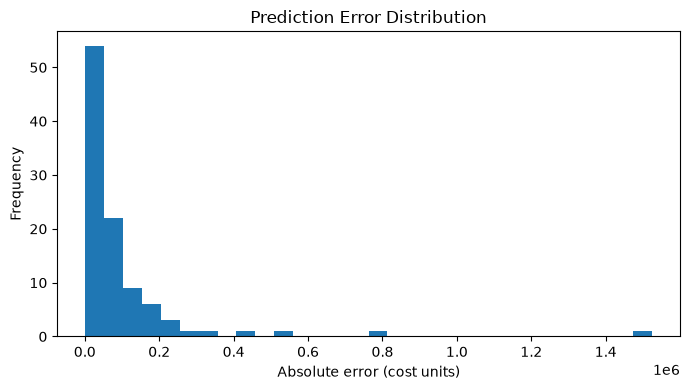

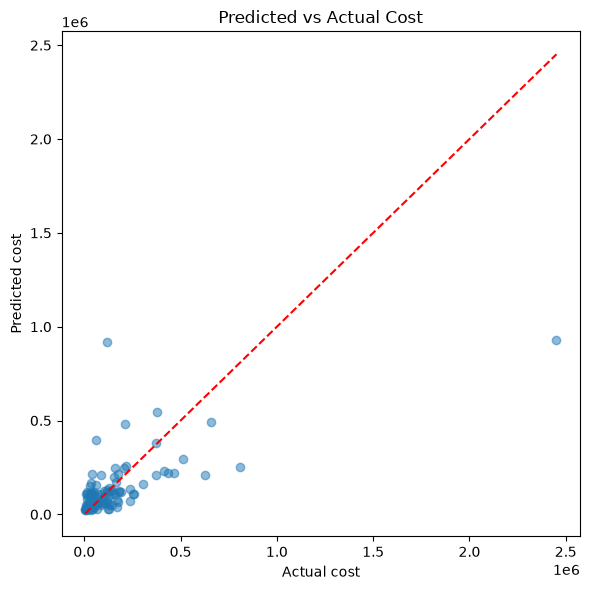

In [16]:

# Model Error Analysis
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Calculate prediction errors using the predictions from the model cell
all_cost_true_arr = np.asarray(all_cost_true).ravel()
all_cost_pred_arr = np.asarray(all_cost_pred).ravel()

residual = all_cost_true_arr - all_cost_pred_arr
abs_err = np.abs(residual)

# Avoid division by zero when calculating relative error
rel_err = abs_err / np.maximum(np.abs(all_cost_true_arr), 1e-9)

# Error metrics in original cost units
print("MAE (cost units):", mean_absolute_error(
    all_cost_true_arr, all_cost_pred_arr
))
print("RMSE (cost units):", np.sqrt(mean_squared_error(
    all_cost_true_arr, all_cost_pred_arr
)))
print("Median absolute error:", np.median(abs_err))
print("Median relative error:", np.median(rel_err))

# Symmetric Mean Absolute Percentage Error
smape = 100 * np.mean(
    2 * abs_err /
    np.maximum(
        np.abs(all_cost_true_arr) + np.abs(all_cost_pred_arr),
        1e-9
    )
)
print("SMAPE (%):", smape)

# Inspect the ten predictions with the largest errors
err_df = X_test.reset_index(drop=True).copy()
err_df["true_cost"] = all_cost_true_arr
err_df["pred_cost"] = all_cost_pred_arr
err_df["abs_err"] = abs_err
err_df["rel_err"] = rel_err

print("\nTop 10 largest absolute errors:")
display(err_df.sort_values("abs_err", ascending=False).head(10))

# Distribution of absolute prediction errors
plt.figure(figsize=(7, 4))
plt.hist(abs_err, bins=30)
plt.xlabel("Absolute error (cost units)")
plt.ylabel("Frequency")
plt.title("Prediction Error Distribution")
plt.tight_layout()
plt.show()

# Actual versus predicted costs
plt.figure(figsize=(6, 6))
plt.scatter(all_cost_true_arr, all_cost_pred_arr, alpha=0.5)

lower = min(all_cost_true_arr.min(), all_cost_pred_arr.min())
upper = max(all_cost_true_arr.max(), all_cost_pred_arr.max())
plt.plot([lower, upper], [lower, upper], "r--")

plt.xlabel("Actual cost")
plt.ylabel("Predicted cost")
plt.title("Predicted vs Actual Cost")
plt.tight_layout()
plt.show()
